In [3]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [4]:
from pathlib import Path #코랩 환경에 맞게 변경
import yaml

# data.yaml 탐색
yaml_files = list(Path("/content/drive/MyDrive/dataset").rglob("data.yaml"))

if len(yaml_files) != 1:
    raise ValueError(f"data.yaml 확인 필요: {yaml_files}")

dataset_dir = yaml_files[0].parent

# YAML 파일 읽기
with open(yaml_files[0], "r", encoding="utf-8") as f:
    data = yaml.safe_load(f)

# 코랩 환경에 맞게 경로 변경
data["path"] = str(dataset_dir)
data["train"] = "/content/drive/MyDrive/dataset/train"
data["val"] = "/content/drive/MyDrive/dataset/valid"
data["test"] = "/content/drive/MyDrive/dataset/test"

# 수정된 YAML 저장
yaml_path = dataset_dir / "colab_data.yaml"

with open(yaml_path, "w", encoding="utf-8") as f:
    yaml.safe_dump(data, f, allow_unicode=True)

print("데이터셋 경로:", dataset_dir)
print("클래스 개수:", data["nc"])
print("클래스 이름:", data["names"])

데이터셋 경로: /content/drive/MyDrive/dataset
클래스 개수: 3
클래스 이름: ['beverage', 'person', 'snack']


In [5]:
for split in ["train", "valid", "test"]: #이미지 개수 세기
    image_dir = dataset_dir / split / "images"

    images = [
        p for p in image_dir.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png", ".webp"]
    ]

    print(f"{split}: {len(images)}장")

train: 351장
valid: 100장
test: 51장


In [6]:
%pip install -U ultralytics

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 41.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3/3 [ultralytics]


In [8]:
from ultralytics import YOLO #모델 학습

#사전학습 모델 불러오기
model = YOLO("yolo26n.pt")

#학습 시작
results = model.train(
    data=str(yaml_path),
    epochs=50,
    imgsz=640,
    batch=16,
    device=0,
    project="/content/runs",
    name="my_yolo_project",
    plots=True
)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/drive/MyDrive/dataset/colab_data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=None, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo26n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=my_yolo_project, nbs=64, nms=None, opset=

In [9]:
#모델평가
best_path = "/content/runs/my_yolo_project/weights/best.pt"

best_model = YOLO(best_path)

metrics = best_model.val(
    data=str(yaml_path),
    split="test"
)

print("Precision:", metrics.box.mp)
print("Recall:", metrics.box.mr)
print("mAP50:", metrics.box.map50)
print("mAP50-95:", metrics.box.map)

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO26n summary (fused): 121 layers, 2,390,221 parameters, 0 gradients, 5.4 GFLOPs
WARNING ⚠️ val: Slow image access detected (ping: 0.4±0.1 ms, read: 32.1±12.4 MB/s, size: 27.6 KB). Use local storage instead of remote/mounted storage for better performance. See https://docs.ultralytics.com/guides/model-training-tips
val: Scanning /content/drive/MyDrive/dataset/test/labels... 51 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 51/51 2.5it/s 20.4s
val: New cache created: /content/drive/MyDrive/dataset/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 4/4 2.2it/s 1.8s
                   all         51        109      0.925      0.904      0.921      0.829
              beverage         21         37      0.983          1      0.995      0.995
                person         12         45      0.819      0.711      0.774      0.5

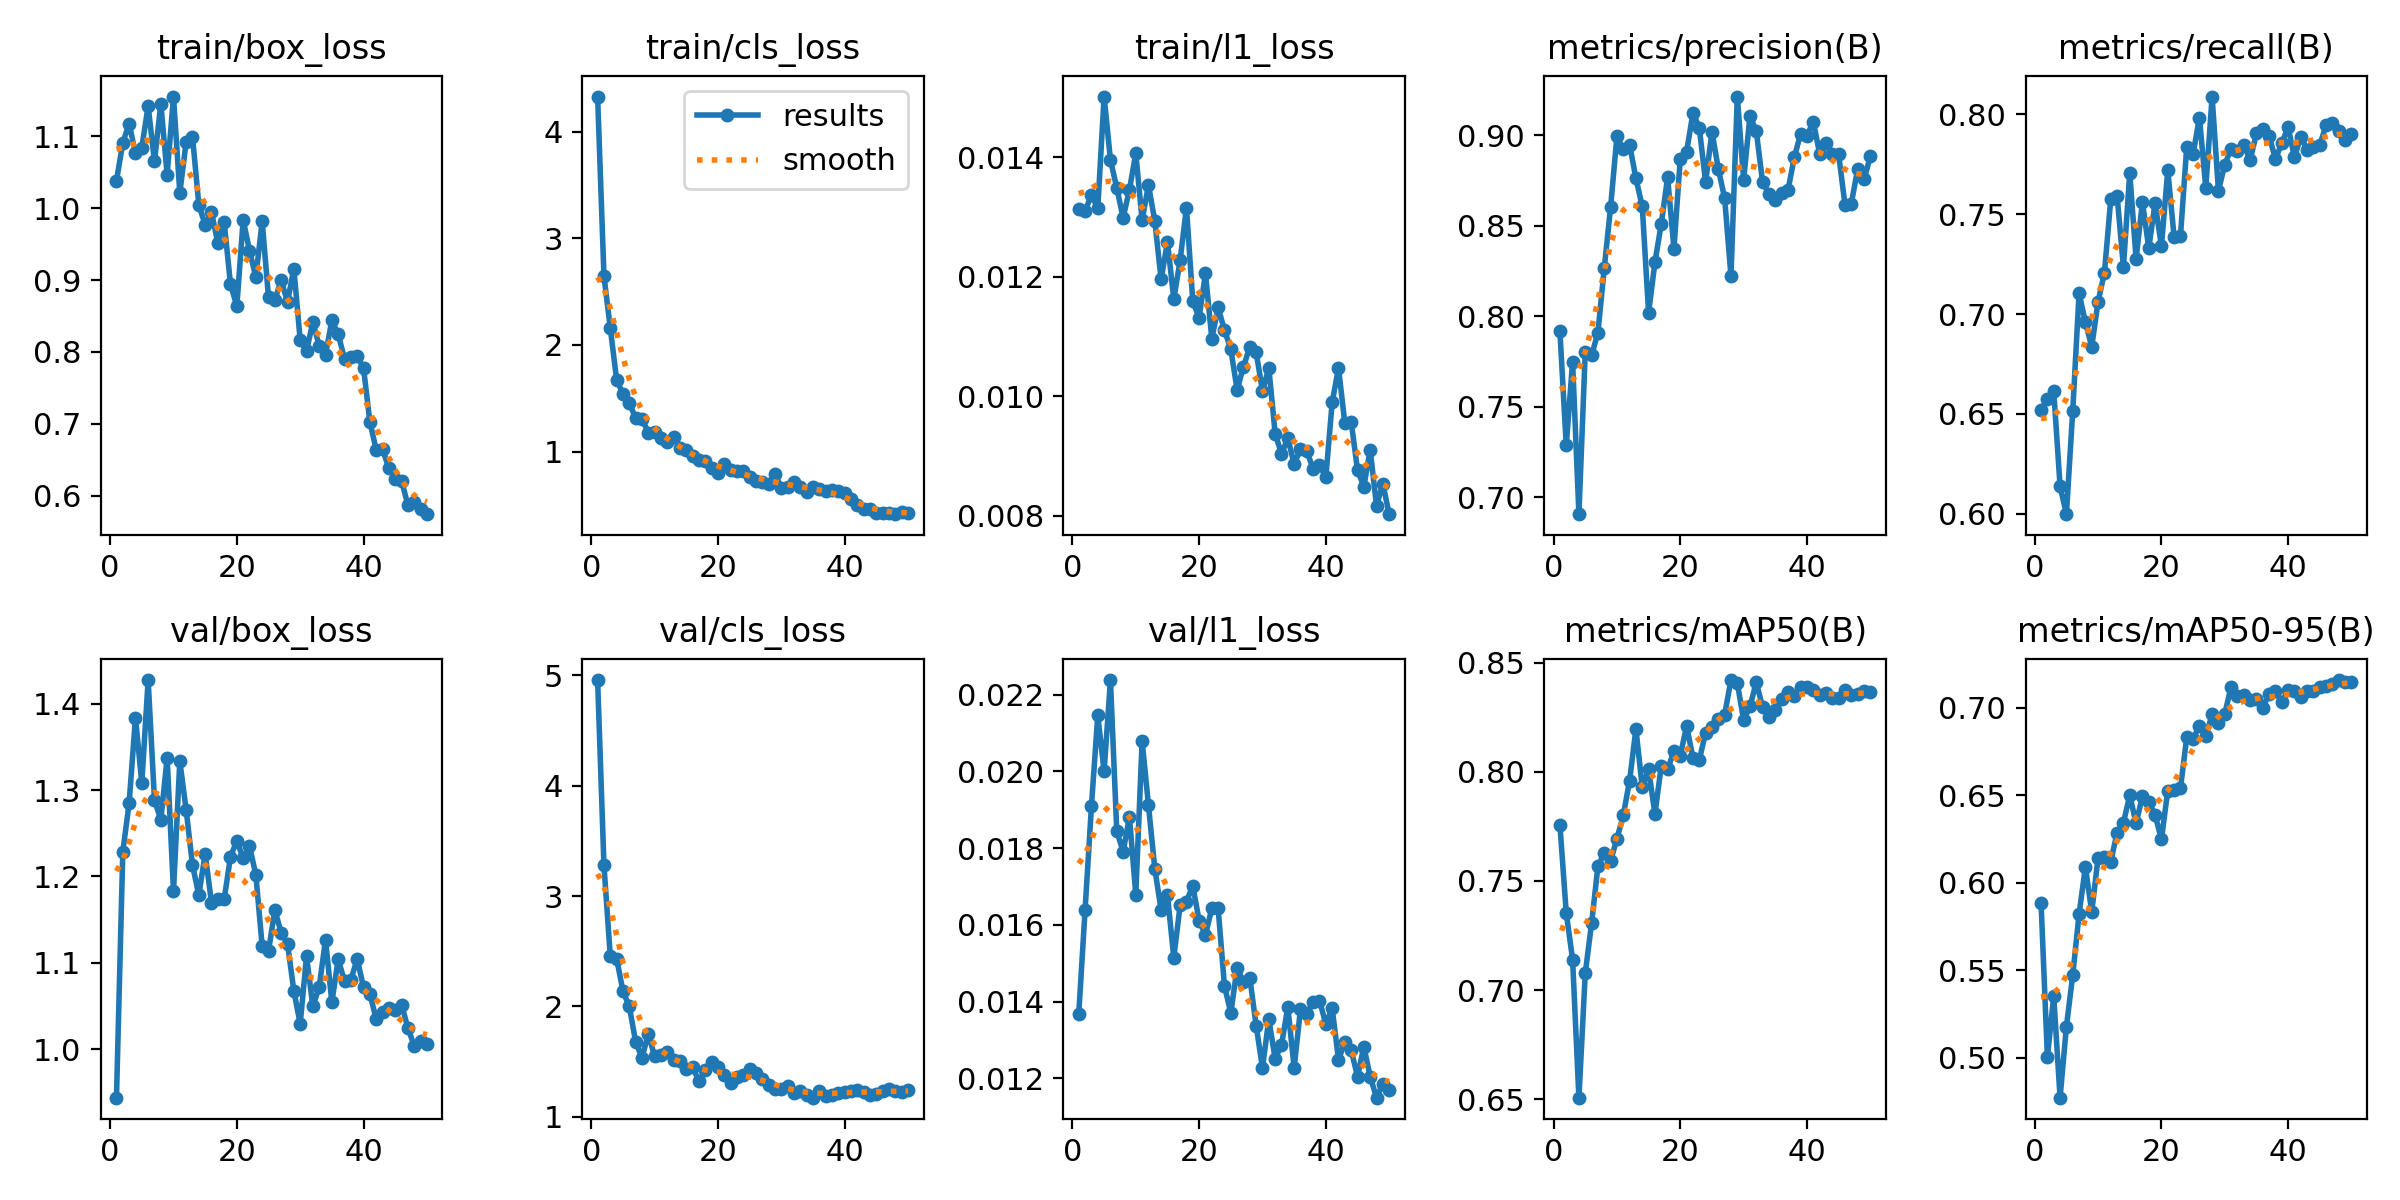

In [10]:
from IPython.display import Image, display

display(Image(filename="/content/runs/my_yolo_project/results.png",width=900))